# 06 · Figures for the README
Produces the charts in `docs/images/` from the data and the **production** pipeline (`src/`). The final model is
fitted on the 80k dev rows exactly as in notebook 05 and evaluated on the same untouched 20k holdout.

In [1]:
import sys; sys.path.insert(0, '..')
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_recall_curve, confusion_matrix
from src.data import DataLoader, TARGET
from src.features import FeatureBuilder, SNAPSHOT
from src.model import FraudModel
from src.train import XGB_TUNED, WEIGHT_POWER

OUT = Path('../docs/images'); OUT.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, GRAY, INK, INK2 = '#2a78d6', '#eb6834', '#8a8984', '#0b0b0b', '#52514e'
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .25, 'axes.titleweight': 'bold', 'axes.titlesize': 12,
                     'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'font.size': 10})

def save(fig, name):
    fig.savefig(OUT / name, bbox_inches='tight', facecolor='white'); plt.show()

train = DataLoader().load('train')
y = train[TARGET]
idx_dev, idx_hold = train_test_split(train.index, test_size=.2, stratify=y, random_state=42)
y_hold = y.loc[idx_hold].to_numpy()

## 1. The leakage: counters that stop when the bank freezes an account

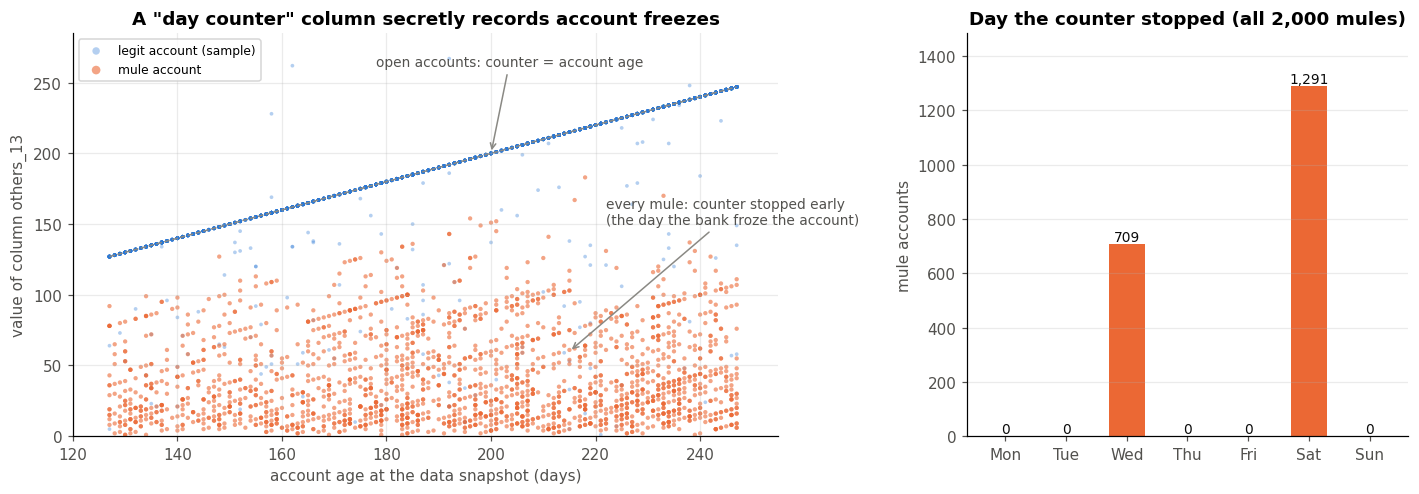

In [2]:
age = (SNAPSHOT - train.account_opening_date).dt.days
legit = train[y == 0].sample(4000, random_state=0)
mules = train[y == 1]
stop_day = (train.account_opening_date + pd.to_timedelta(train.others_13, unit='D')).dt.day_name()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [1.6, 1]})
a1.scatter(age[legit.index], legit.others_13, s=6, color=BLUE, alpha=.35, edgecolors='none', label='legit account (sample)')
a1.scatter(age[mules.index], mules.others_13, s=8, color=ORANGE, alpha=.6, edgecolors='none', label='mule account')
a1.plot([127, 247], [127, 247], color=GRAY, ls='--', lw=1)
a1.annotate('open accounts: counter = account age', xy=(200, 200), xytext=(178, 262), color=INK2, fontsize=9,
            arrowprops=dict(arrowstyle='->', color=GRAY))
a1.annotate('every mule: counter stopped early\n(the day the bank froze the account)', xy=(215, 60), xytext=(222, 150), color=INK2,
            fontsize=9, arrowprops=dict(arrowstyle='->', color=GRAY))
a1.set(xlim=(120, 255), ylim=(0, 285), xlabel='account age at the data snapshot (days)', ylabel='value of column others_13',
       title='A "day counter" column secretly records account freezes')
a1.legend(loc='upper left', fontsize=8, markerscale=2)
days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
cnt = stop_day[y == 1].value_counts().reindex(days, fill_value=0)
a2.bar([d[:3] for d in days], cnt.values, color=[ORANGE if v else '#d6d5d0' for v in cnt.values], width=.6)
for i, v in enumerate(cnt.values):
    a2.text(i, v, f'{v:,}', ha='center', va='bottom', fontsize=9, color=INK)
a2.set(ylabel='mule accounts', title='Day the counter stopped (all 2,000 mules)', ylim=(0, cnt.max() * 1.15))
a2.grid(axis='x')
plt.tight_layout(); save(fig, 'leakage.png')

## 2. Who are the mules?

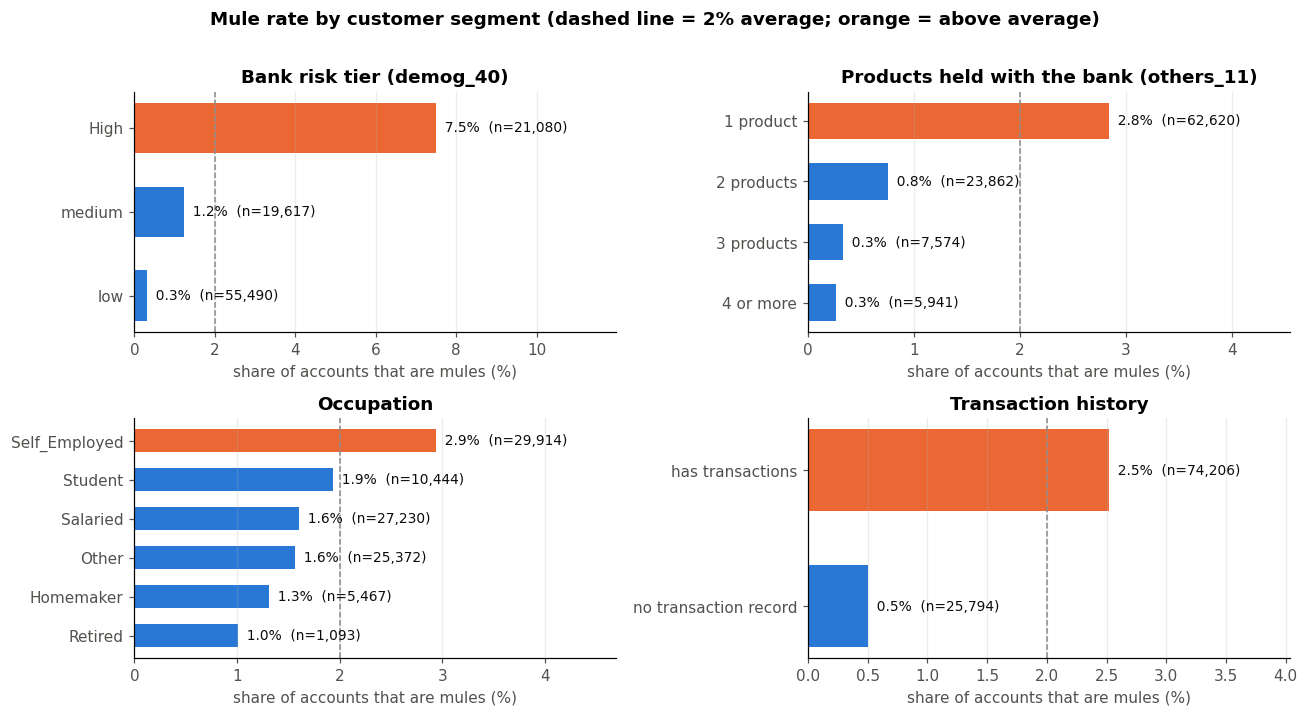

In [3]:
def rate(s):
    g = y.groupby(s).agg(['mean', 'size'])
    return g['mean'] * 100, g['size']

panels = []
tier = train.demog_40.map({'low': 'low', 'medium': 'medium', 'High': 'High'})
panels.append(('Bank risk tier (demog_40)', *rate(tier), ['low', 'medium', 'High']))
prods = train.others_11.clip(upper=4).map({1: '1 product', 2: '2 products', 3: '3 products', 4: '4 or more'})
panels.append(('Products held with the bank (others_11)', *rate(prods), ['4 or more', '3 products', '2 products', '1 product']))
occ = train.occupation.where(train.occupation.isin(['Self_Employed', 'Salaried', 'Student', 'Homemaker', 'Retired', 'Other']))
r, n = rate(occ)
panels.append(('Occupation', r, n, list(r.sort_values().index)))
dormant = train.txn_1.isna().map({True: 'no transaction record', False: 'has transactions'})
panels.append(('Transaction history', *rate(dormant), ['no transaction record', 'has transactions']))

fig, axes = plt.subplots(2, 2, figsize=(12, 6.4))
for ax, (title, r, n, order) in zip(axes.flat, panels):
    r, n = r.reindex(order), n.reindex(order)
    ax.barh(order, r.values, color=[ORANGE if v > 2 else BLUE for v in r.values], height=.6)
    for i, (v, k) in enumerate(zip(r.values, n.values)):
        ax.text(v, i, f'  {v:.1f}%  (n={k:,})', va='center', fontsize=9, color=INK)
    ax.axvline(2, color=GRAY, ls='--', lw=1)
    ax.set(title=title, xlim=(0, max(r.max() * 1.6, 4))); ax.set_xlabel('share of accounts that are mules (%)')
    ax.grid(axis='y')
fig.suptitle('Mule rate by customer segment (dashed line = 2% average; orange = above average)', fontweight='bold', y=1.01)
plt.tight_layout(); save(fig, 'mule_profile.png')

## 3. Final model on the untouched holdout (production code, fitted on dev only)

threshold 0.41: caught 347, missed 53, false alarms 28, correctly cleared 19572 | top 2% -> 89% of mules


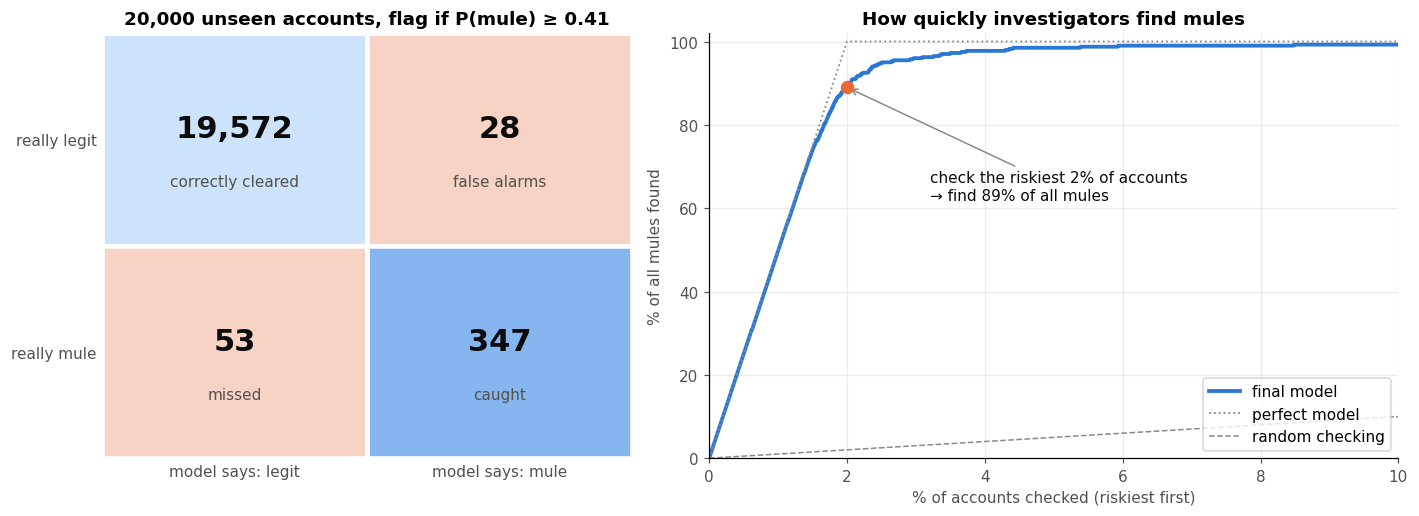

In [4]:
model = FraudModel(XGB_TUNED, WEIGHT_POWER).fit(train.loc[idx_dev])
p = model.predict_proba(train.loc[idx_hold])
pr, rc, thr = precision_recall_curve(y.loc[idx_dev], model.oof_)
t = thr[np.argmax(2 * pr[:-1] * rc[:-1] / (pr[:-1] + rc[:-1] + 1e-12))]          # chosen on dev, not on the holdout
tn, fp, fn, tp = confusion_matrix(y_hold, p >= t).ravel()
order = np.argsort(-p)
found = np.cumsum(y_hold[order]) / y_hold.sum() * 100
pct = np.arange(1, len(p) + 1) / len(p) * 100
top2 = found[int(.02 * len(p)) - 1]
print(f'threshold {t:.2f}: caught {tp}, missed {fn}, false alarms {fp}, correctly cleared {tn} | top 2% -> {top2:.0f}% of mules')

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={'width_ratios': [1, 1.3]})
cells = [[(tn, 'correctly cleared'), (fp, 'false alarms')], [(fn, 'missed'), (tp, 'caught')]]
shade = [['#cde2fb', '#f6d3c4'], ['#f6d3c4', '#86b6ef']]
for i in range(2):
    for j in range(2):
        v, lab = cells[i][j]
        a1.add_patch(plt.Rectangle((j, 1 - i), 1, 1, color=shade[i][j], ec='white', lw=3))
        a1.text(j + .5, 1.55 - i, f'{v:,}', ha='center', va='center', fontsize=20, fontweight='bold', color=INK)
        a1.text(j + .5, 1.3 - i, lab, ha='center', va='center', fontsize=10, color=INK2)
a1.set(xlim=(0, 2), ylim=(0, 2), xticks=[.5, 1.5], yticks=[1.5, .5], title=f'20,000 unseen accounts, flag if P(mule) ≥ {t:.2f}')
a1.set_xticklabels(['model says: legit', 'model says: mule']); a1.set_yticklabels(['really legit', 'really mule'])
a1.grid(False); a1.tick_params(length=0)
for s in a1.spines.values():
    s.set_visible(False)
a2.plot(pct, found, color=BLUE, lw=2.5, label='final model')
a2.plot([0, 2, 10], [0, 100, 100], color=GRAY, ls=':', lw=1.2, label='perfect model')
a2.plot([0, 10], [0, 10], color=GRAY, ls='--', lw=1, label='random checking')
a2.scatter([2], [top2], color=ORANGE, s=60, zorder=4)
a2.annotate(f'check the riskiest 2% of accounts\n→ find {top2:.0f}% of all mules', xy=(2, top2), xytext=(3.2, 62), color=INK, fontsize=10,
            arrowprops=dict(arrowstyle='->', color=GRAY))
a2.set(xlim=(0, 10), ylim=(0, 102), xlabel='% of accounts checked (riskiest first)', ylabel='% of all mules found',
       title='How quickly investigators find mules'); a2.legend(loc='lower right')
plt.tight_layout(); save(fig, 'performance.png')

## 4. Are the probabilities honest?

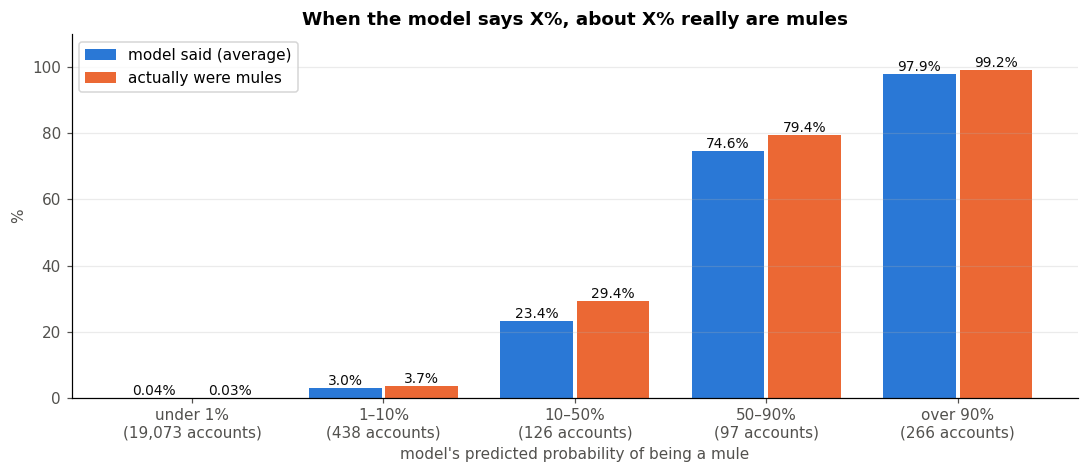

overall: predicted 1.92% vs actual 2.00%


In [5]:
edges, labels = [0, .01, .1, .5, .9, 1], ['under 1%', '1–10%', '10–50%', '50–90%', 'over 90%']
b = pd.cut(p, edges, labels=labels, include_lowest=True)
cal = pd.DataFrame({'p': p, 'y': y_hold, 'b': b}).groupby('b', observed=True).agg(pred=('p', 'mean'), actual=('y', 'mean'), n=('y', 'size'))
fig, ax = plt.subplots(figsize=(10, 4.4))
x = np.arange(len(cal))
ax.bar(x - .2, cal.pred * 100, .38, color=BLUE, label='model said (average)')
ax.bar(x + .2, cal.actual * 100, .38, color=ORANGE, label='actually were mules')
for i, (pv, av) in enumerate(zip(cal.pred * 100, cal.actual * 100)):
    ax.text(i - .2, pv, f'{pv:.1f}%' if pv >= .1 else f'{pv:.2f}%', ha='center', va='bottom', fontsize=9, color=INK)
    ax.text(i + .2, av, f'{av:.1f}%' if av >= .1 else f'{av:.2f}%', ha='center', va='bottom', fontsize=9, color=INK)
ax.set_xticks(x, [f'{l}\n({n:,} accounts)' for l, n in zip(cal.index, cal.n)])
ax.set(xlabel="model's predicted probability of being a mule", ylabel='%', ylim=(0, 110),
       title='When the model says X%, about X% really are mules'); ax.legend(loc='upper left'); ax.grid(axis='x')
plt.tight_layout(); save(fig, 'calibration.png')
print(f'overall: predicted {p.mean():.2%} vs actual {y_hold.mean():.2%}')

## 5. What drives the predictions (SHAP)

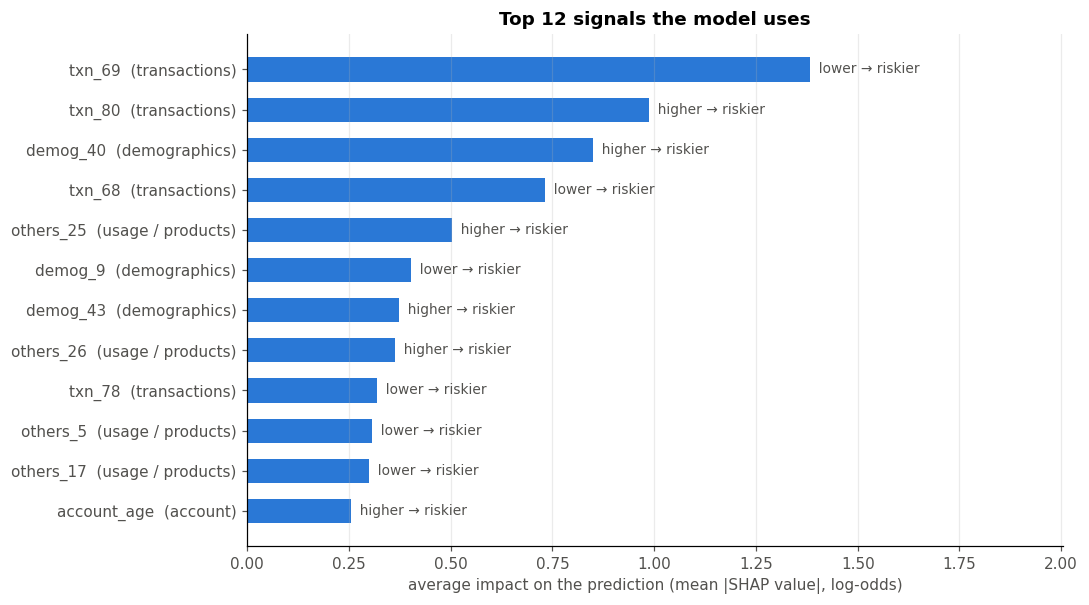

{'txn_69': 'lower → riskier', 'txn_80': 'higher → riskier', 'demog_40': 'higher → riskier', 'txn_68': 'lower → riskier', 'others_25': 'higher → riskier', 'demog_9': 'lower → riskier', 'demog_43': 'higher → riskier', 'others_26': 'higher → riskier', 'txn_78': 'lower → riskier', 'others_5': 'lower → riskier', 'others_17': 'lower → riskier', 'account_age': 'higher → riskier'}


In [6]:
Xh = model.features_.transform(train.loc[idx_hold])
dm = xgb.DMatrix(Xh, enable_categorical=True)
shap = np.mean([m.get_booster().predict(dm, pred_contribs=True)[:, :-1] for m in model.cv_.models_], axis=0)
shap = pd.DataFrame(shap, columns=Xh.columns, index=Xh.index)
top = shap.abs().mean().sort_values(ascending=False).head(12)
group = lambda c: ('transactions' if c.startswith('txn') else 'usage / products' if c.startswith('others')
                   else 'demographics' if c.startswith('demog') else 'account')
def direction(c):
    v = Xh[c]
    if isinstance(v.dtype, pd.CategoricalDtype):
        return 'category'
    ok = v.notna()
    rho = pd.Series(v[ok].rank()).corr(pd.Series(shap.loc[ok, c].rank()))
    return 'higher → riskier' if rho > 0 else 'lower → riskier'
fig, ax = plt.subplots(figsize=(10, 5.6))
names = [f'{c}  ({group(c)})' for c in top.index][::-1]
ax.barh(names, top.values[::-1], color=BLUE, height=.6)
for i, c in enumerate(top.index[::-1]):
    ax.text(top[c], i, f'  {direction(c)}', va='center', fontsize=9, color=INK2)
ax.set(xlabel='average impact on the prediction (mean |SHAP value|, log-odds)', xlim=(0, top.max() * 1.45),
       title='Top 12 signals the model uses'); ax.grid(axis='y')
plt.tight_layout(); save(fig, 'top_features.png')
print({c: direction(c) for c in top.index})